In [4]:
import os
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tikzplotlib
from tqdm import tqdm
import json

In [6]:
out_dir = "/media/signet/9b222db5-110f-45ae-b7ca-0f12241ce80b/multimodal/deleteme/"
camps = os.listdir(out_dir)


dfs = []
for c in tqdm(camps):
    with open(out_dir+c+"/config.json", 'r') as f:
        config = json.load(f)
    if config["mode"] == 2:
        df = pd.read_csv(out_dir+c+"/evaluate_data_4.csv")
        df['campaign'] = int(c.split('_')[1])
        dfs.append(df)
df = pd.concat(dfs)

  0%|          | 0/465 [00:00<?, ?it/s]

100%|██████████| 465/465 [01:55<00:00,  4.02it/s]


/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and wil

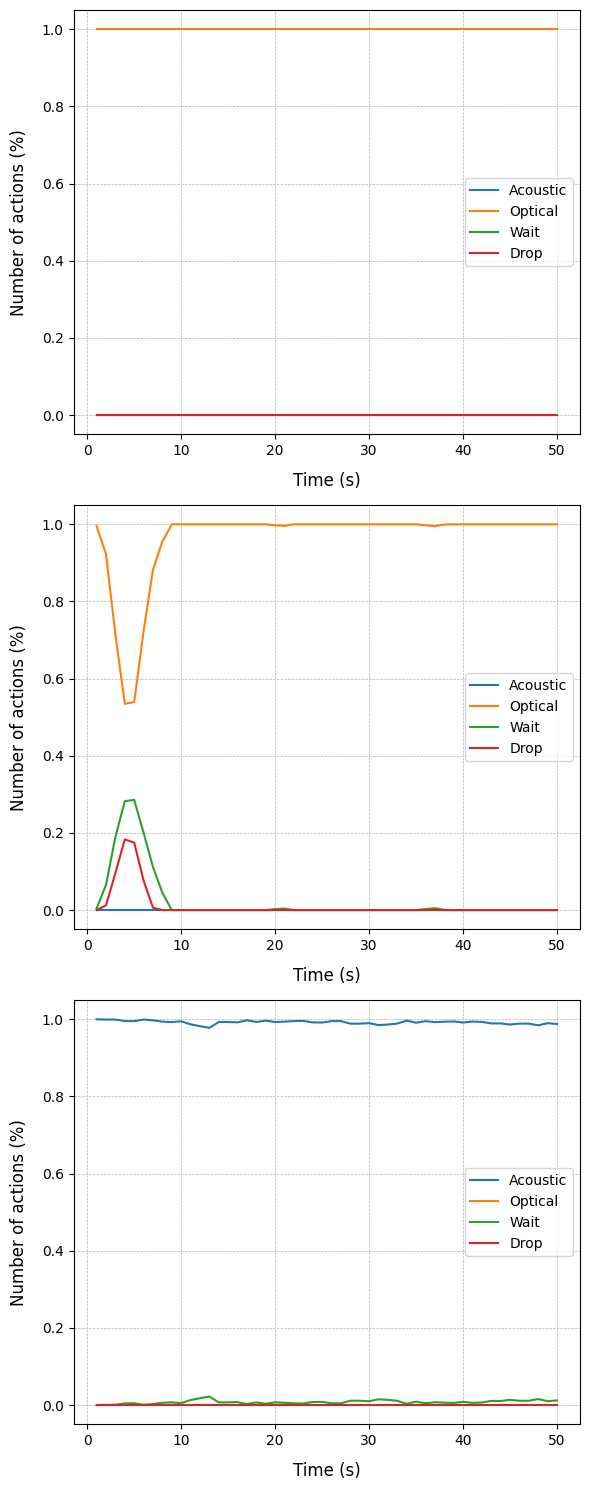

In [7]:
df_copy = df.copy()
df_copy['Action Time'] = np.round(df_copy['Action Time']/60)
df_copy = df_copy[df_copy['Action Time'] <= 50]

palette = sns.color_palette("tab10", n_colors=4)


import matplotlib.pylab as pylab
params = {'axes.labelsize': 12}
pylab.rcParams.update(params)

labelpad = 10
fig, ax = plt.subplots(3,1, figsize=(3*2,3*2.5*2))
plt.sca(ax[0])
sns.lineplot(data=df_copy[df_copy['agent'] == 0], x='Action Time', y='Acoustic', errorbar=None, c=palette[0], label='Acoustic', ax=ax[0])
sns.lineplot(data=df_copy[df_copy['agent'] == 0], x='Action Time', y='Optical', errorbar=None, c=palette[1], label='Optical', ax=ax[0])
sns.lineplot(data=df_copy[df_copy['agent'] == 0], x='Action Time', y='Wait', errorbar=None, c=palette[2], label='Wait', ax=ax[0])
sns.lineplot(data=df_copy[df_copy['agent'] == 0], x='Action Time', y='Drop', errorbar=None, c=palette[3], label='Drop', ax=ax[0])
plt.ylabel('Number of actions (%)', labelpad=labelpad)
plt.xlabel('Time (s)', labelpad=labelpad)
plt.grid(True, linestyle='--', linewidth=0.5)
# plt.tight_layout()
# plt.savefig("agent_0.pdf", bbox_inches='tight')
# plt.savefig("agent_0.png", dpi=300, bbox_inches='tight')
# tikzplotlib.save("action_over_time_agent_0.tex")
# plt.show()

plt.sca(ax[1])
sns.lineplot(data=df_copy[df_copy['agent'] == 1], x='Action Time', y='Acoustic', errorbar=None, c=palette[0], label='Acoustic', ax=ax[1])
sns.lineplot(data=df_copy[df_copy['agent'] == 1], x='Action Time', y='Optical', errorbar=None, c=palette[1], label='Optical', ax=ax[1])
sns.lineplot(data=df_copy[df_copy['agent'] == 1], x='Action Time', y='Wait', errorbar=None, c=palette[2], label='Wait', ax=ax[1])
sns.lineplot(data=df_copy[df_copy['agent'] == 1], x='Action Time', y='Drop', errorbar=None, c=palette[3], label='Drop', ax=ax[1])
plt.ylabel('Number of actions (%)', labelpad=labelpad)
plt.xlabel('Time (s)', labelpad=labelpad)
plt.grid(True, linestyle='--', linewidth=0.5)
# plt.tight_layout()
# plt.savefig("agent_1.pdf", bbox_inches='tight')
# plt.savefig("agent_1.png", dpi=300, bbox_inches='tight')
# tikzplotlib.save("action_over_time_agent_1.tex")
# plt.show()

plt.sca(ax[2])
sns.lineplot(data=df_copy[df_copy['agent'] == 2], x='Action Time', y='Acoustic', errorbar=None, c=palette[0], label='Acoustic', ax=ax[2])
sns.lineplot(data=df_copy[df_copy['agent'] == 2], x='Action Time', y='Optical', errorbar=None, c=palette[1], label='Optical', ax=ax[2])
sns.lineplot(data=df_copy[df_copy['agent'] == 2], x='Action Time', y='Wait', errorbar=None, c=palette[2], label='Wait', ax=ax[2])
sns.lineplot(data=df_copy[df_copy['agent'] == 2], x='Action Time', y='Drop', errorbar=None, c=palette[3], label='Drop', ax=ax[2])
plt.ylabel('Number of actions (%)', labelpad=labelpad)
plt.xlabel('Time (s)', labelpad=labelpad)
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()
# plt.savefig("agent_2.pdf", bbox_inches='tight')
# plt.savefig("agent_2.png", dpi=300, bbox_inches='tight')
tikzplotlib.save("/home/signet/test_out/action_over_time_orig.tex")
plt.show()